In [ ]:
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential, save_model
from tensorflow.keras.layers import Conv1D, Conv1DTranspose, Dense, BatchNormalization, Activation, Input
from tensorflow.keras.constraints import max_norm
import matplotlib.pyplot as plt
import numpy as np
import math

In [ ]:
#confirm that GPU is used
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


In [ ]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

%cd /content/drive/Shareddrives/Statistics\ and\ Data\ Analysis/Lectures/DL lectures/Lecture 17/Examples/
!ls

Mounted at /content/drive/
/content/drive/My Drive/Didattica/Corsi/AI/Lectures/Lecture3/DenoisingAE
 AE_denoise.ipynb  'Data access.ipynb'	    MC_Methods.ipynb
 data		    Generate_pulses.ipynb


In [ ]:
# Load data
data_noisy = np.load('./data/signal_waves_noisy.npy')
x_val_noisy, y_val_noisy = data_noisy[:,0], data_noisy[:,1]
data_pure = np.load('./data/signal_waves.npy')
x_val_pure, y_val_pure = data_pure[:,0], data_pure[:,1]

In [ ]:
np.shape(x_val_noisy)
test = y_val_noisy[0]

In [ ]:
normalize = True

noisy_input = np.zeros(len(y_val_noisy))
pure_input  = np.zeros(len(y_val_noisy))
scale_factors = np.ones(len(y_val_noisy))

#rescale the pulse shape to take Y values between 0 and 1
if normalize:
    # Reshape data
    y_val_noisy_r = []
    y_val_pure_r = []
    y_scale_factor = []

    for i in range(0, len(y_val_noisy)):
        noisy_sample = y_val_noisy[i]
        pure_sample = y_val_pure[i]

        scale_factor = 1. / np.max(noisy_sample) #compute the scale factor on the noisy ps
        noisy_sample = noisy_sample * scale_factor
        pure_sample  = pure_sample  * scale_factor

        y_val_noisy_r.append(noisy_sample)
        y_val_pure_r.append(pure_sample)
        y_scale_factor.append(scale_factor)

    noisy_input   = np.array(y_val_noisy_r)
    pure_input    = np.array(y_val_pure_r)
    scale_factors = np.array(y_scale_factor)


# Use the shapes as they are. No normalization.
else:
    noisy_input   = np.array(y_val_noisy)
    pure_input    = np.array(y_val_pure)

In [ ]:
# Model configuration
input_shape = (600, 1)
batch_size = 150
no_epochs = 10
train_test_split = 0.2
validation_split = 0.2
verbosity = 1
max_norm_value = 2.0
kernel_size = 5

In [ ]:
print(np.shape(noisy_input))
# Train/test split
percentage_training = math.floor((1 - train_test_split) * len(noisy_input))
noisy_input, noisy_input_test = noisy_input[:percentage_training], noisy_input[percentage_training:]
pure_input, pure_input_test = pure_input[:percentage_training], pure_input[percentage_training:]

print(np.shape(noisy_input))

(200000, 600)
(160000, 600)


In [ ]:
# Create the model
model = Sequential()


#model.add(Conv1D(512, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform', input_shape=input_shape))
#model.add(Conv1D(128, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform'))
#model.add(Conv1D(32, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform'))
#model.add(Conv1DTranspose(32, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform'))
#model.add(Conv1DTranspose(128, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform'))
#model.add(Conv1DTranspose(512, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='relu', kernel_initializer='he_uniform'))
#model.add(Conv1D(1, kernel_size=kernel_size, kernel_constraint=max_norm(max_norm_value), activation='sigmoid', padding='same'))
#model.compile(optimizer='adam', loss='binary_crossentropy')


model.add(Input(shape=(600,)))
model.add(Dense(256))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(Dense(128))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(Dense(32))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(Dense(128))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(Dense(256))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(Dense(600))
model.add(Activation('linear'))
model.compile(optimizer='adam', loss='mean_squared_error')

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       153,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 600)            │       154,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 600)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385,528 (1.47 MB)

 Trainable params: 383,928 (1.46 MB)

 Non-trainable params: 1,600 (6.25 KB)

In [ ]:
# fit data
history = model.fit(noisy_input, pure_input,
                    epochs=no_epochs,
                    batch_size=batch_size,
                    validation_split=validation_split)

Epoch 1/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.0050 - val_loss: 6.6195e-04
Epoch 2/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 7.2597e-04 - val_loss: 5.5708e-04
Epoch 3/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 5.4741e-04 - val_loss: 2.6014e-04
Epoch 4/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 4.3589e-04 - val_loss: 4.1044e-04
Epoch 5/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 3.6791e-04 - val_loss: 2.1586e-04
Epoch 6/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 3.0321e-04 - val_loss: 2.2984e-04
Epoch 7/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 2.6651e-04 - val_loss: 2.2620e-04
Epoch 8/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 2.4244e-04 - val_loss: 2.3133e-04
Epoch 9/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 2.1519e-04 - val_loss: 2.3601e-04
Epoch 10/10
854/854 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.9236e-04 - val_loss: 1.3226e-04


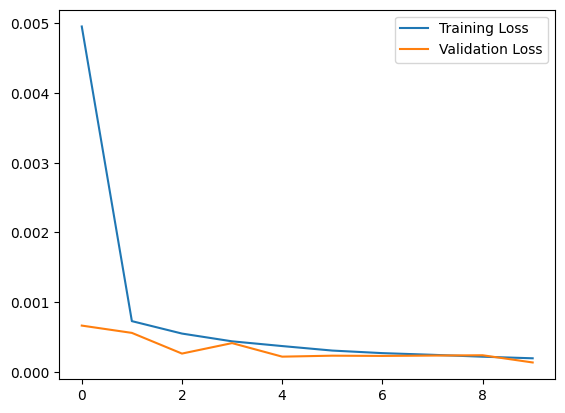

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 179ms/step


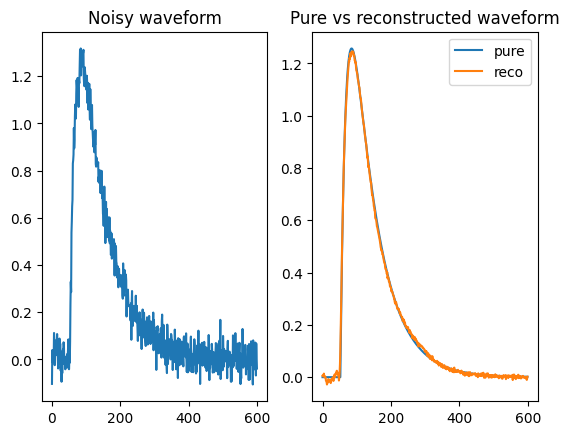

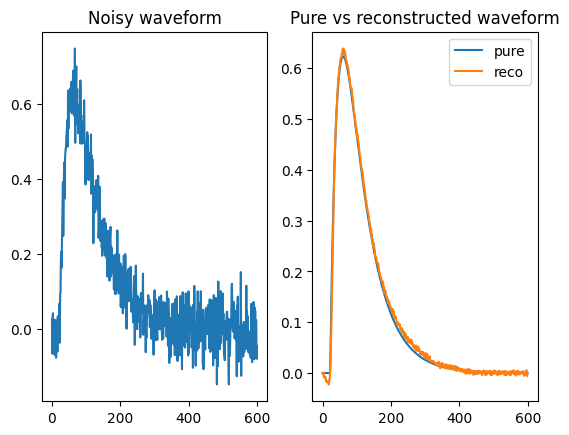

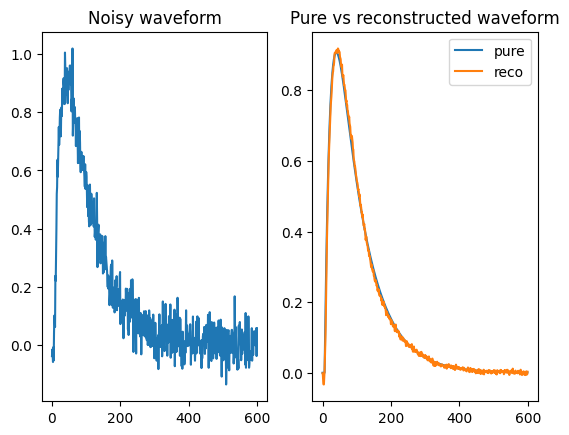

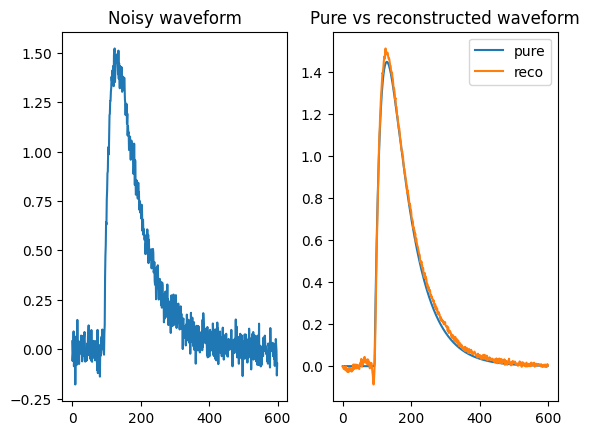

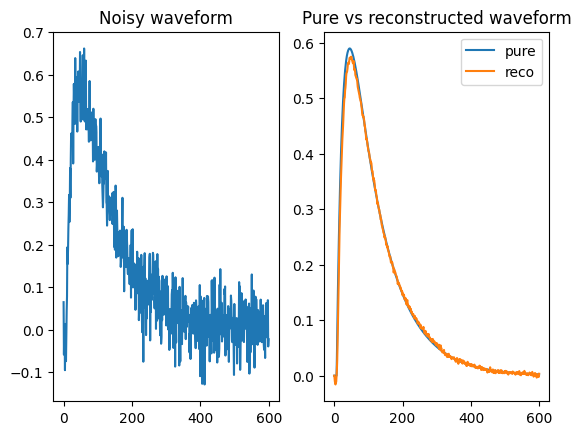

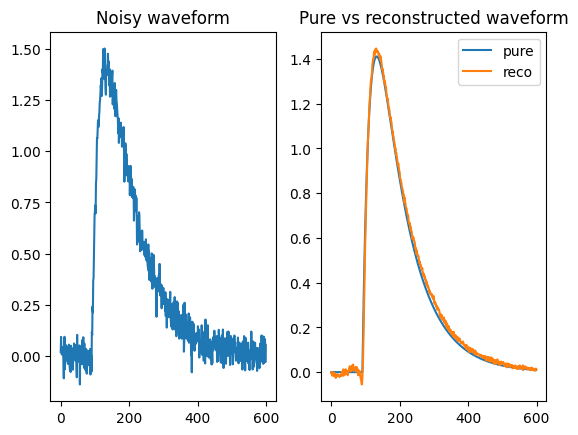

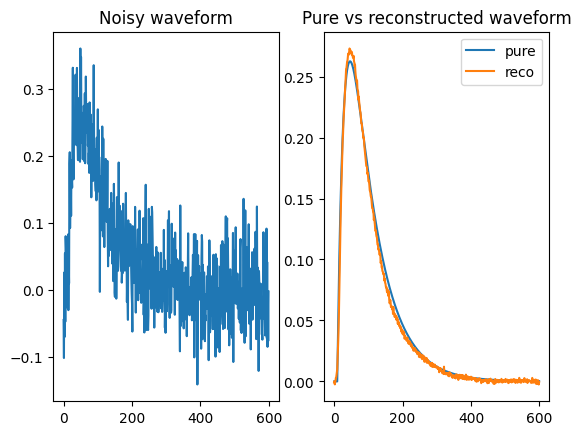

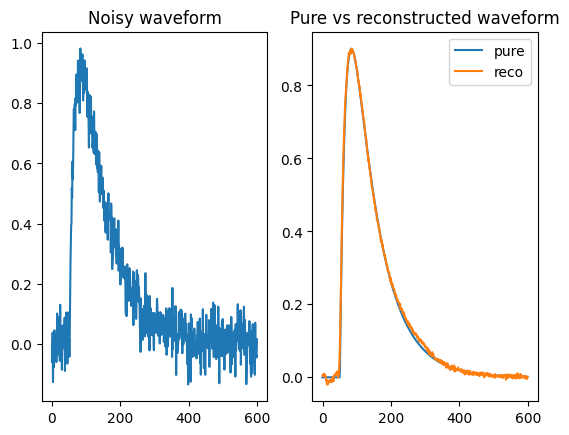

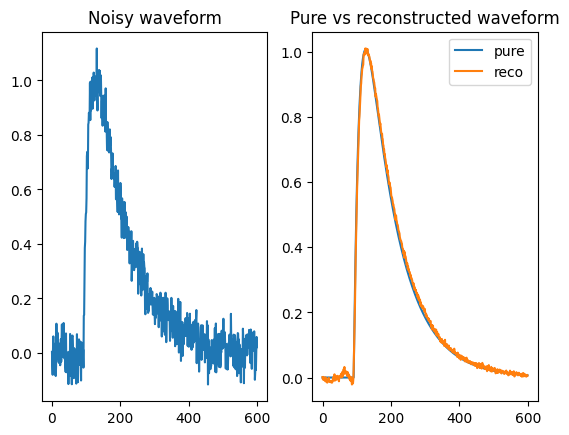

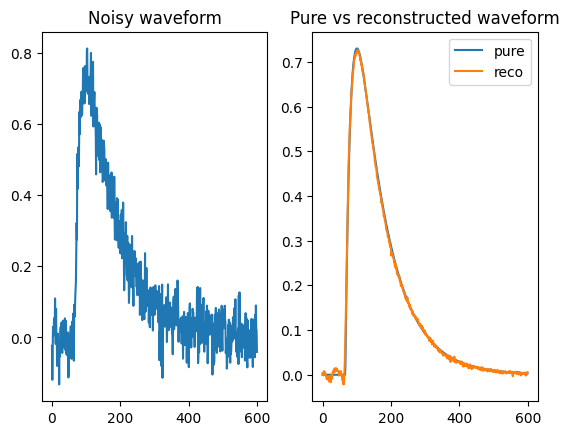

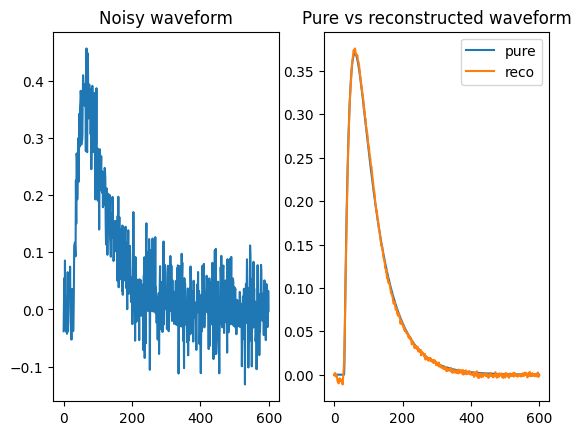

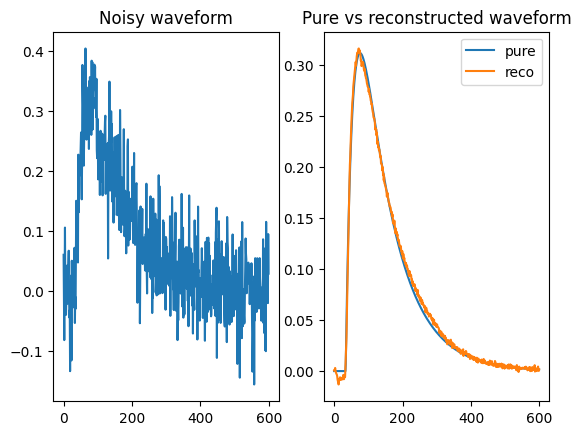

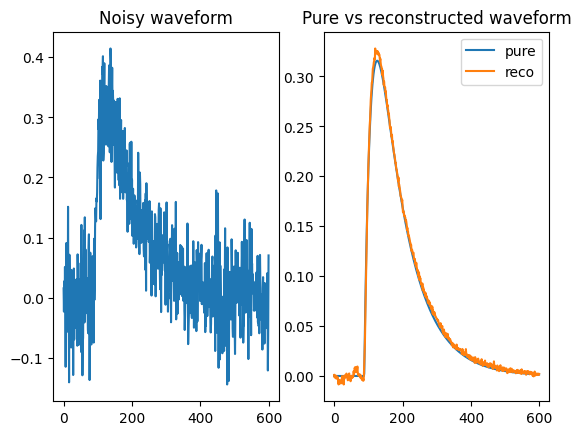

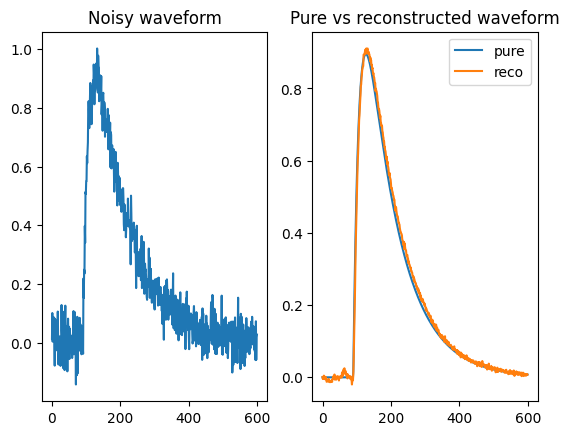

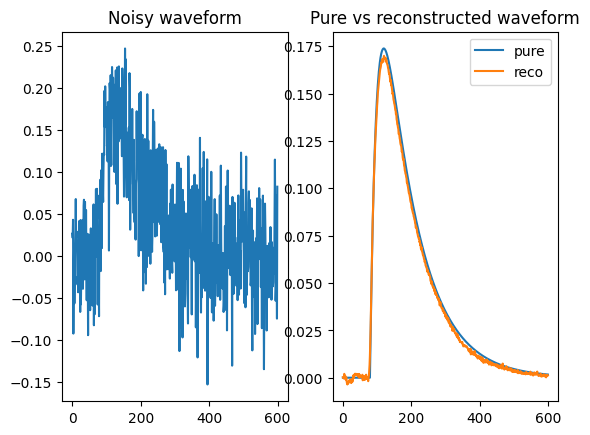

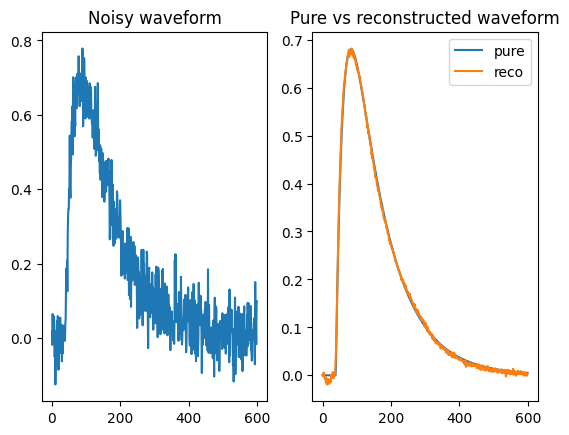

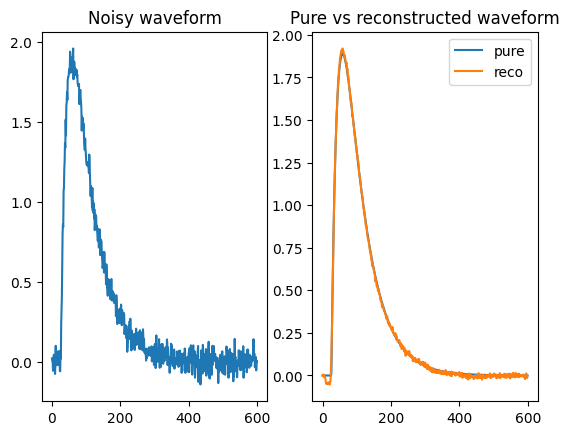

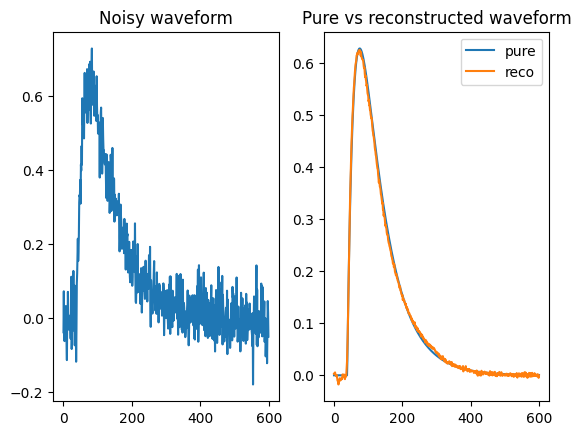

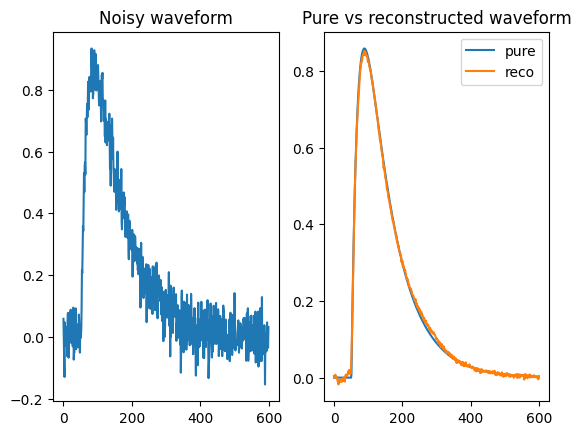

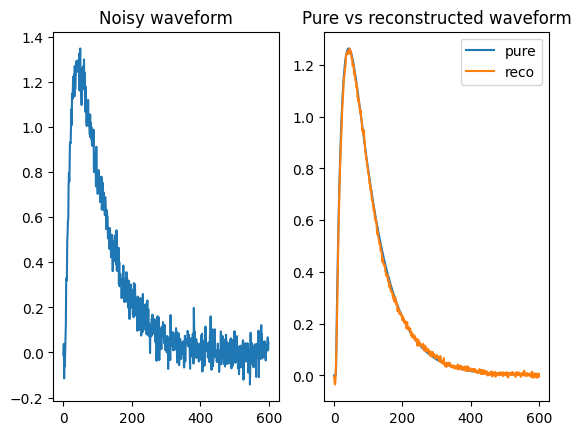

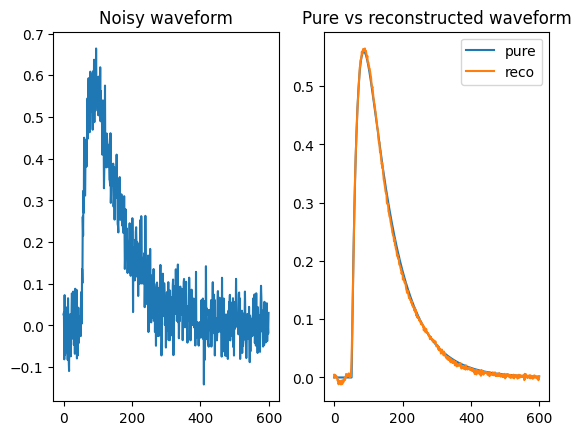

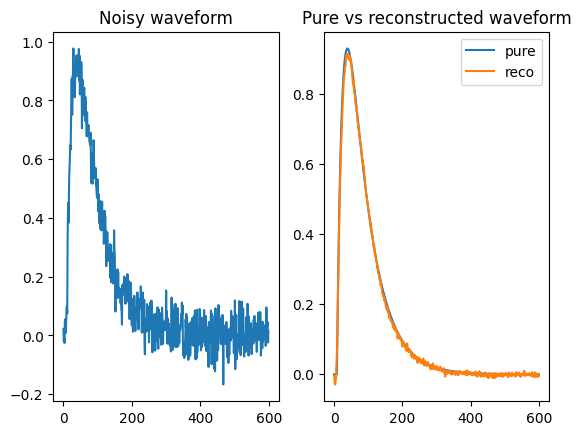

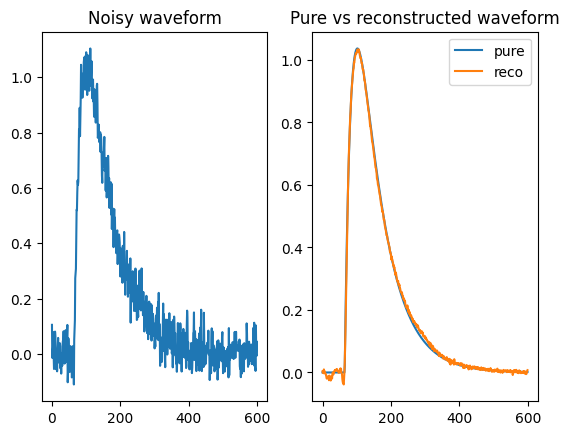

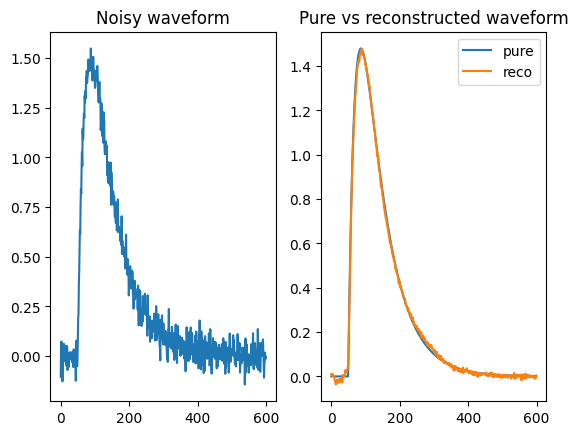

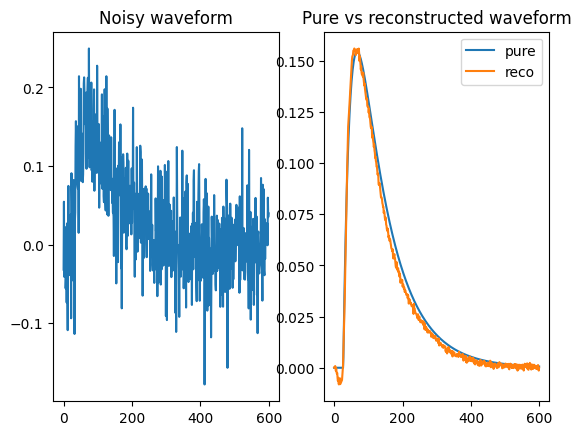

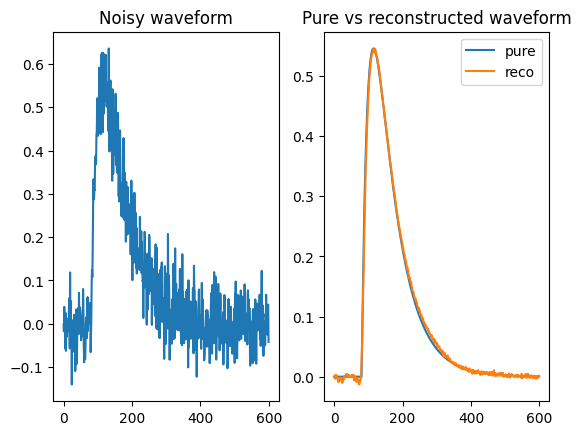

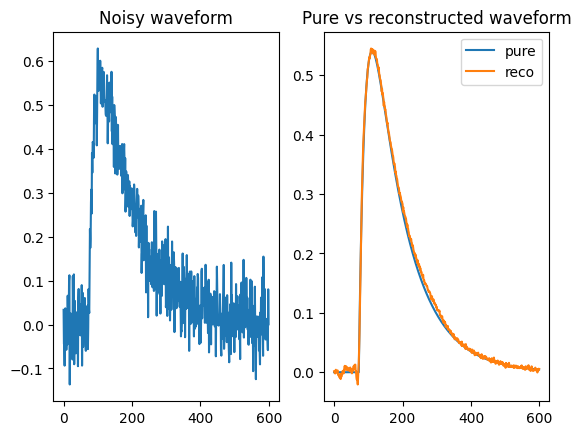

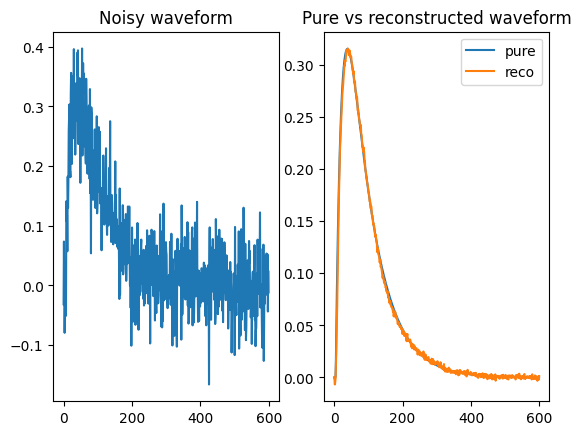

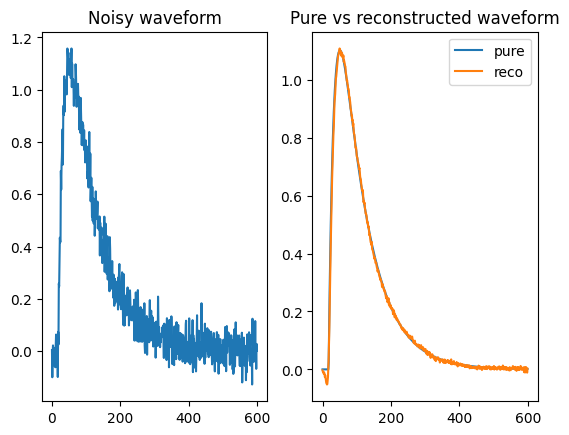

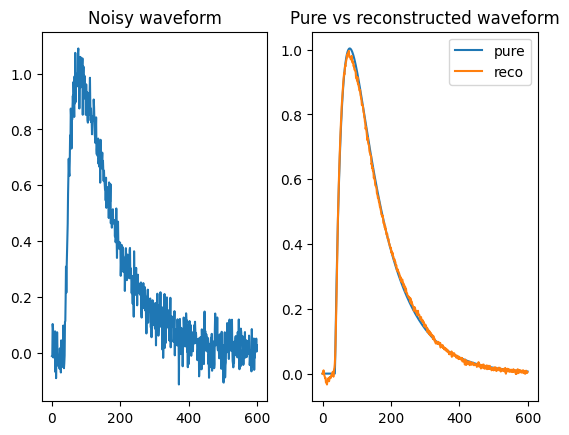

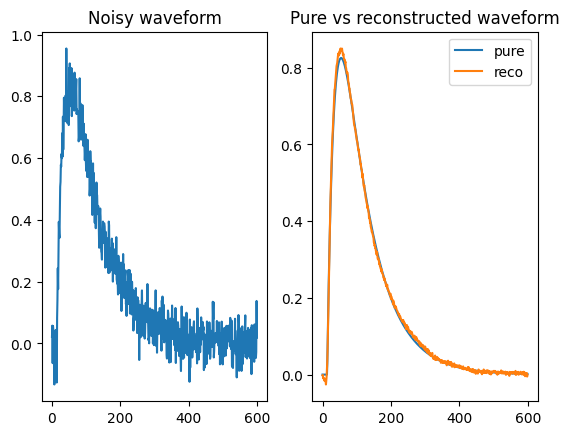

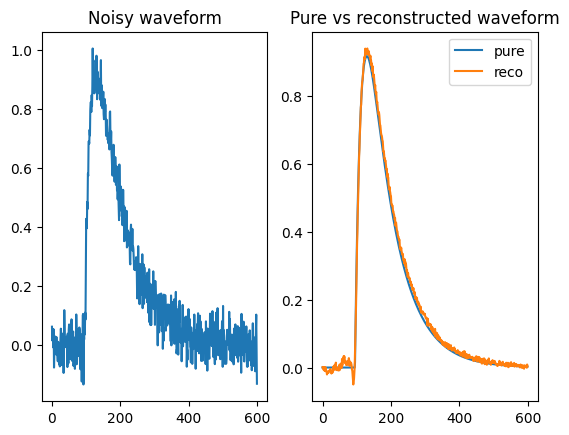

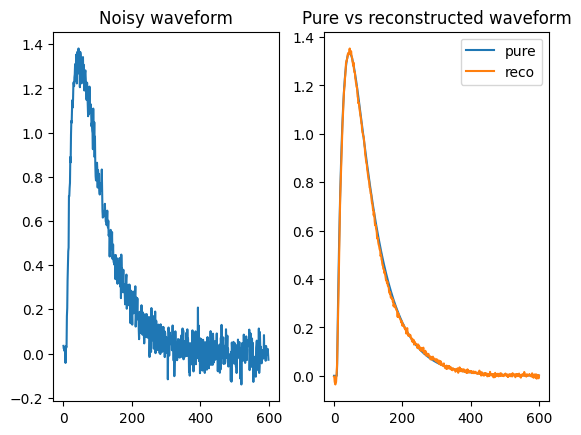

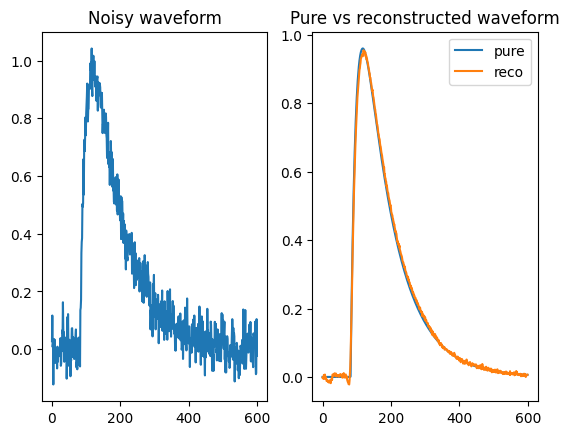

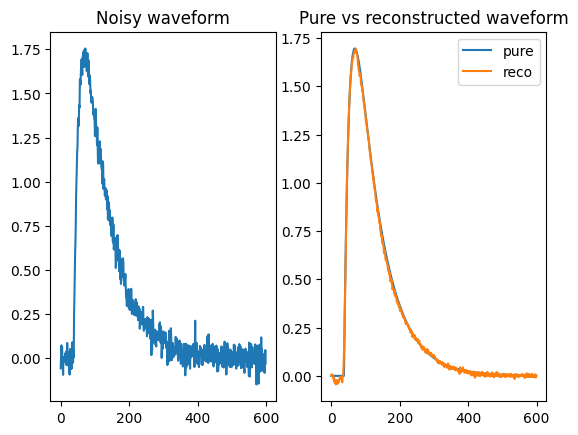

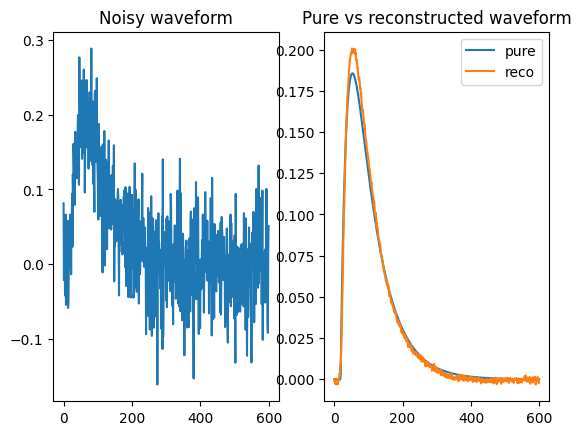

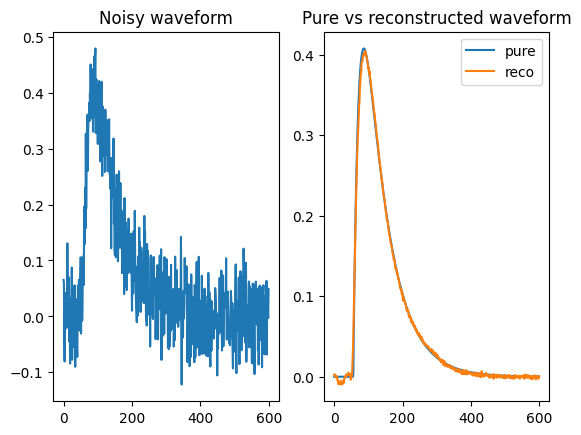

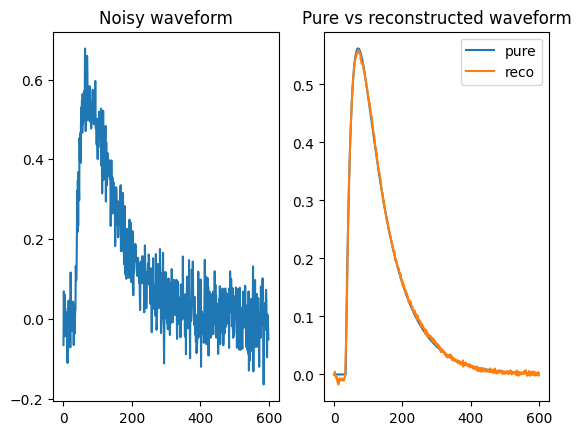

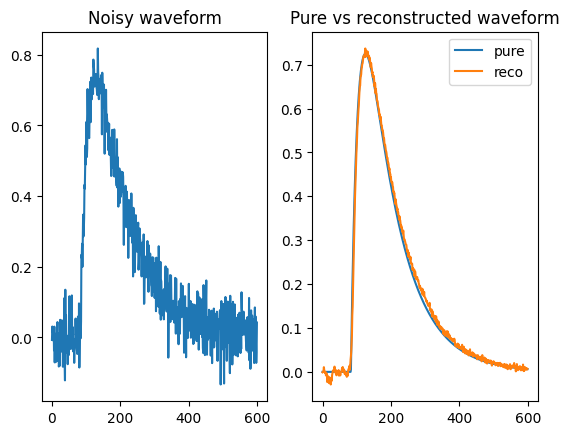

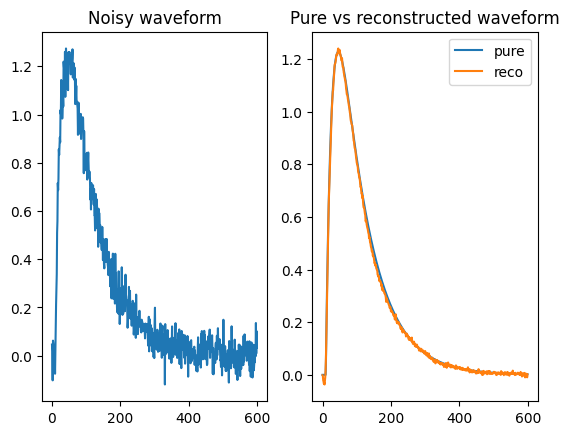

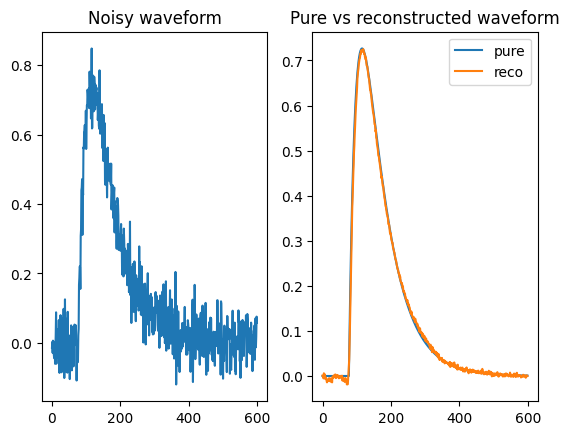

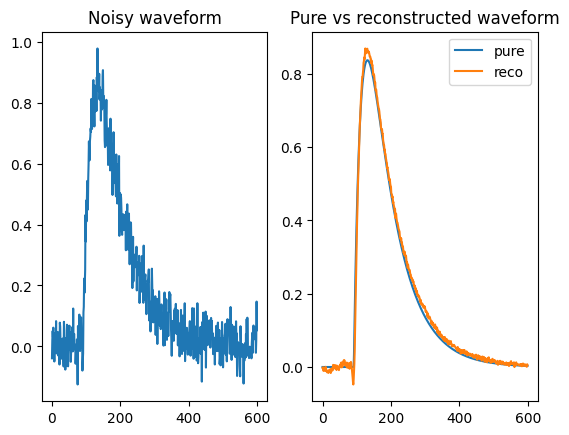

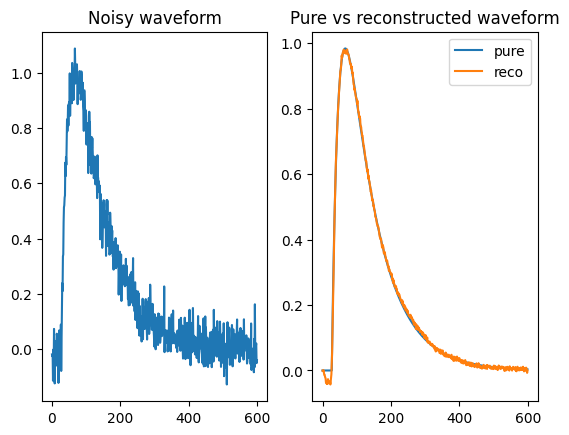

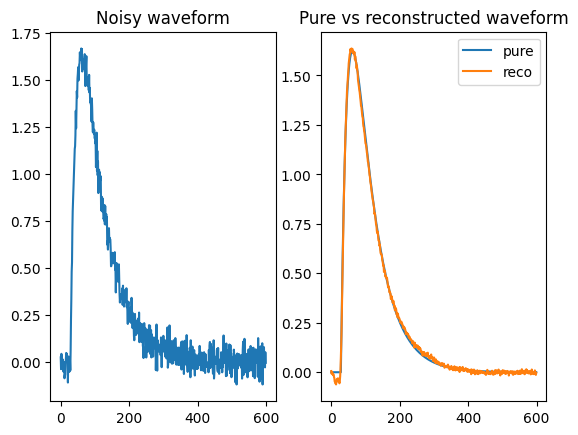

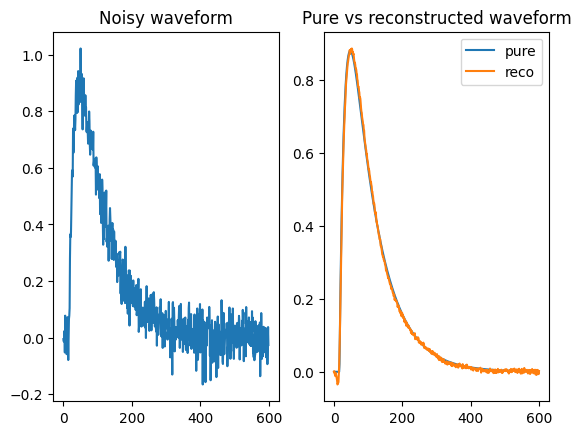

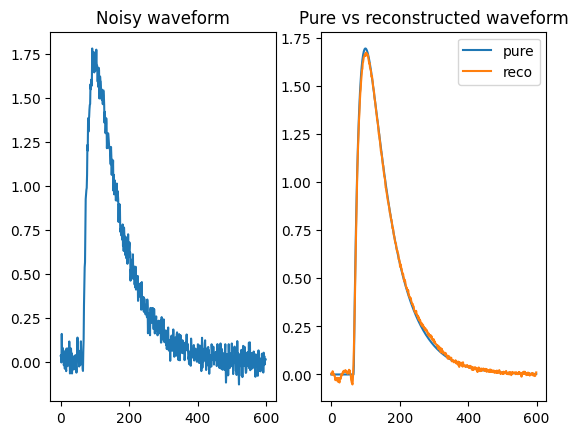

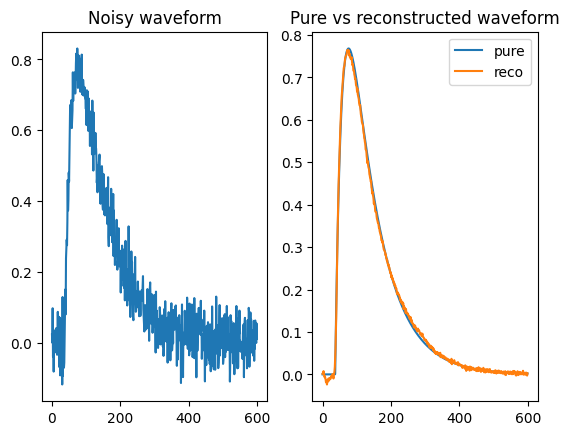

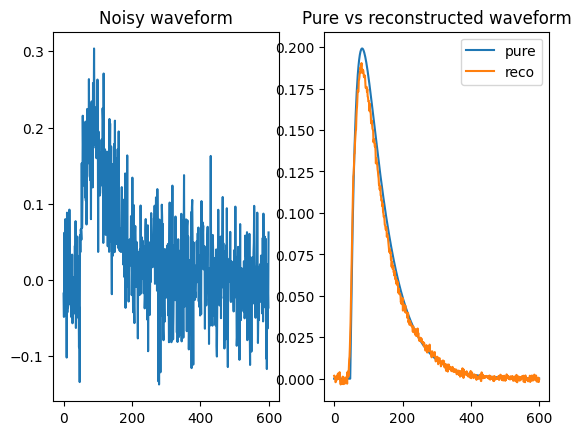

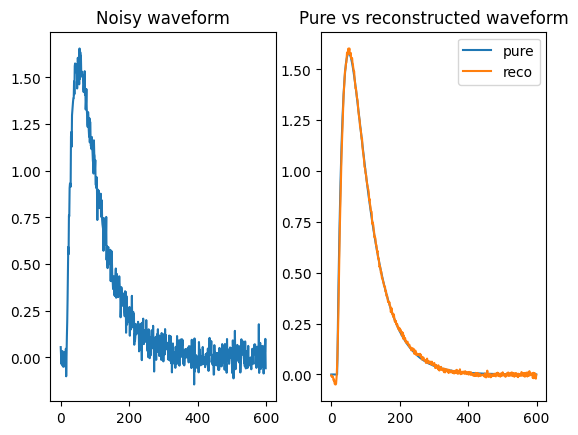

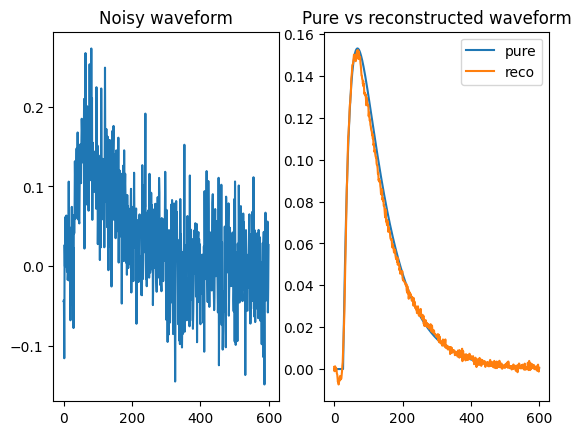

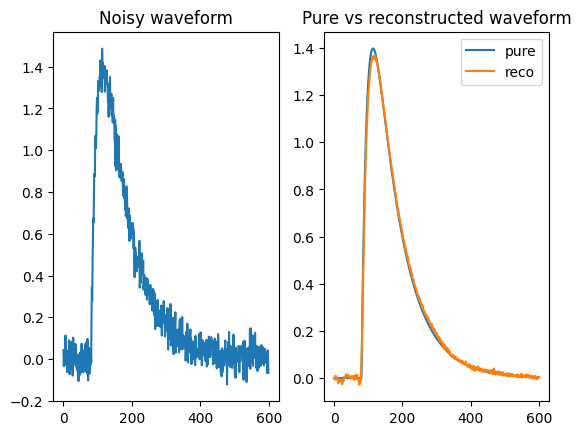

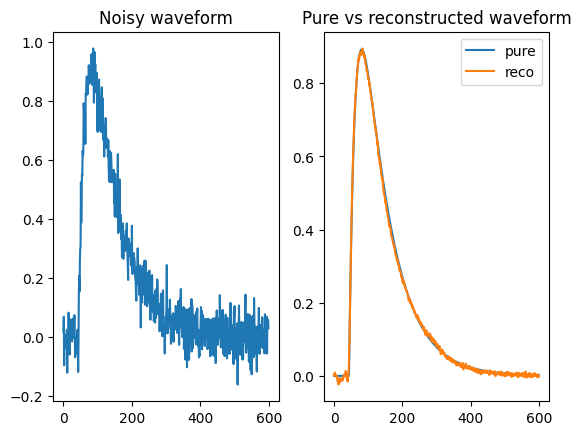

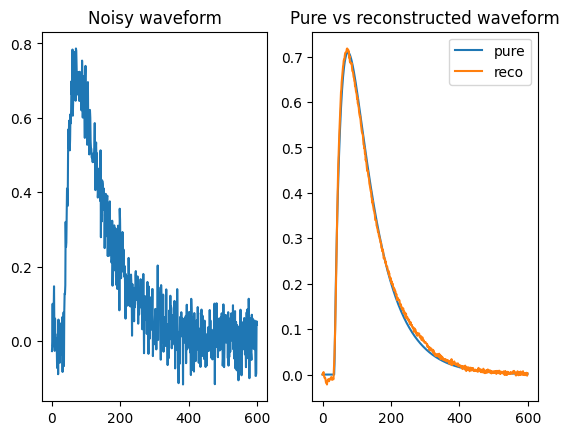

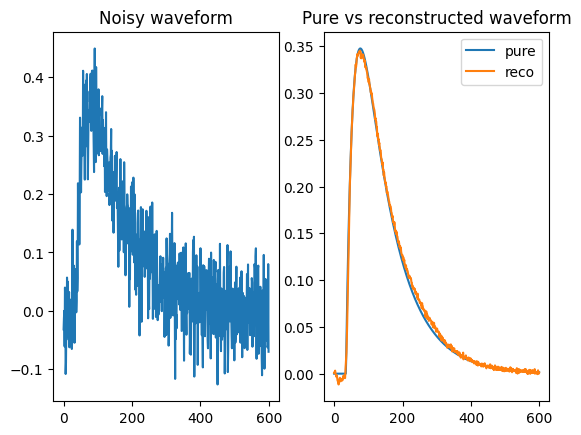

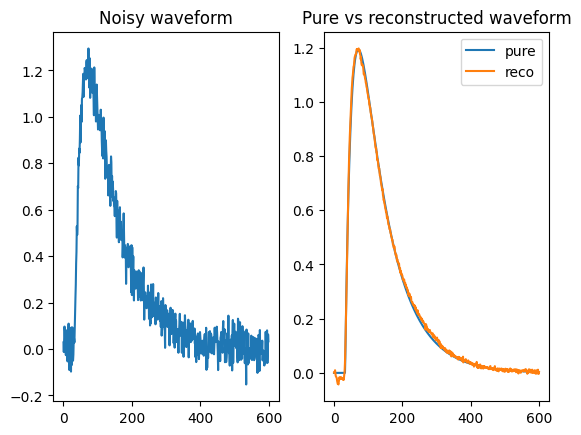

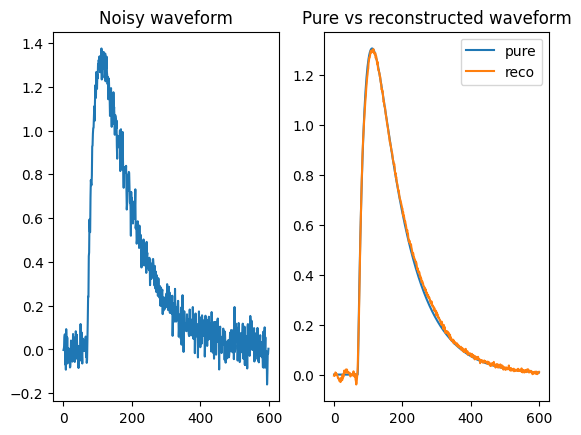

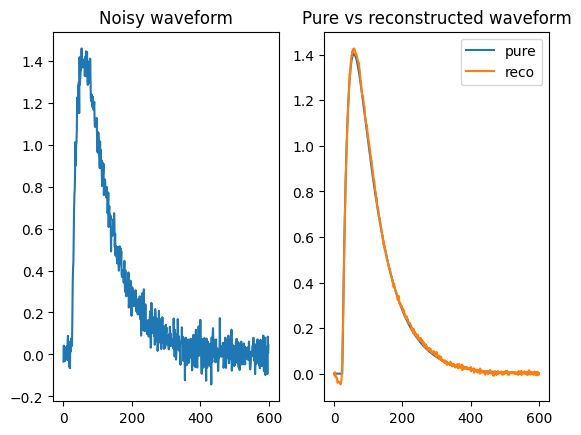

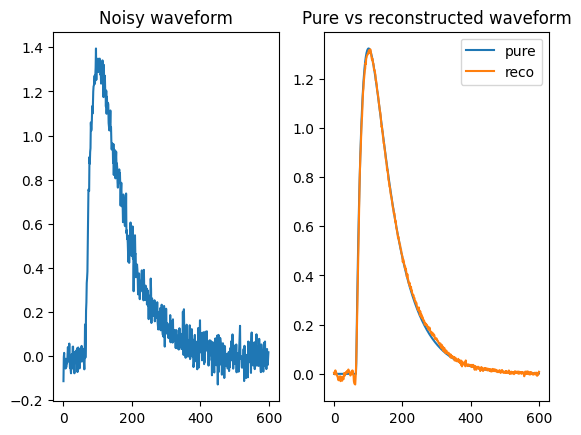

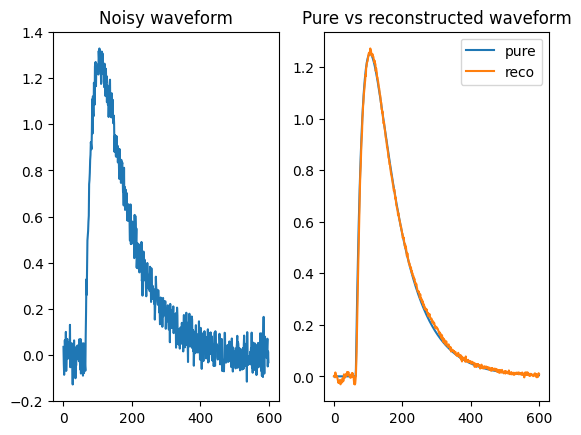

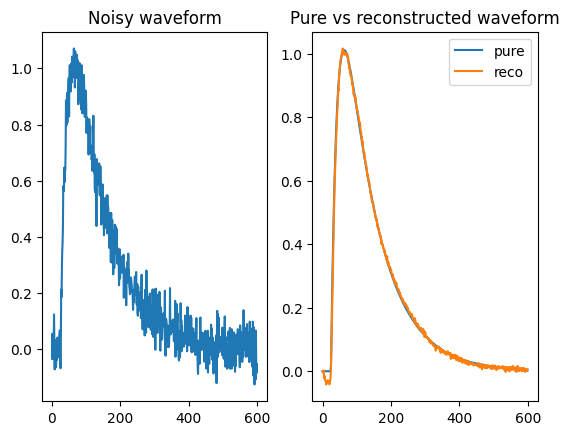

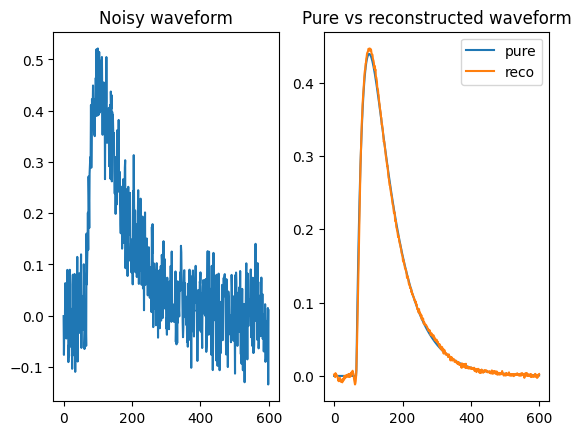

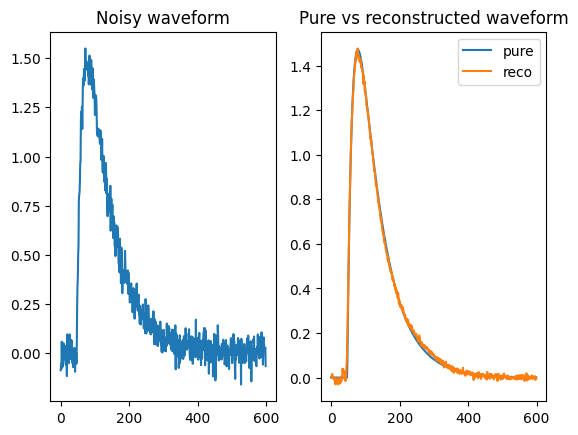

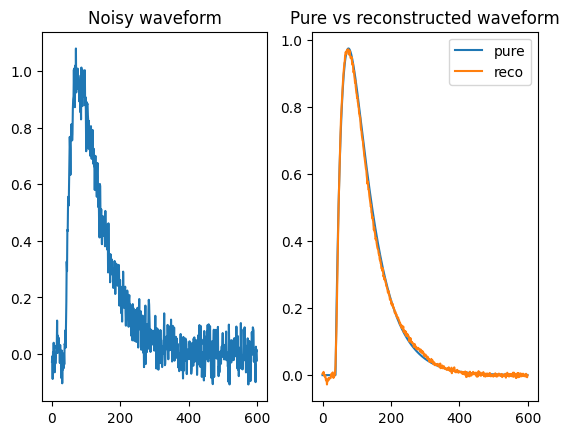

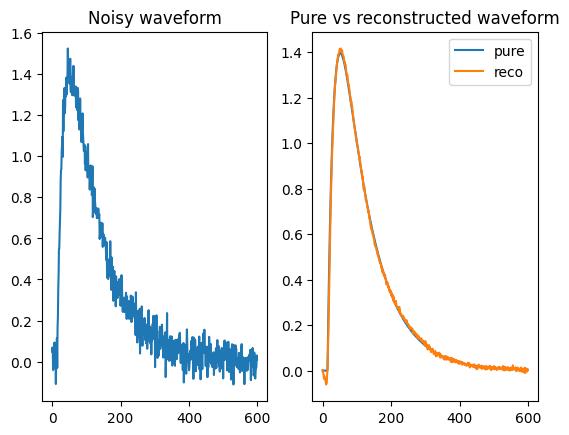

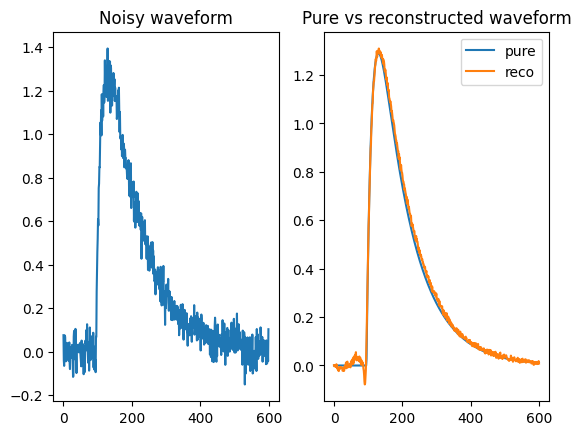

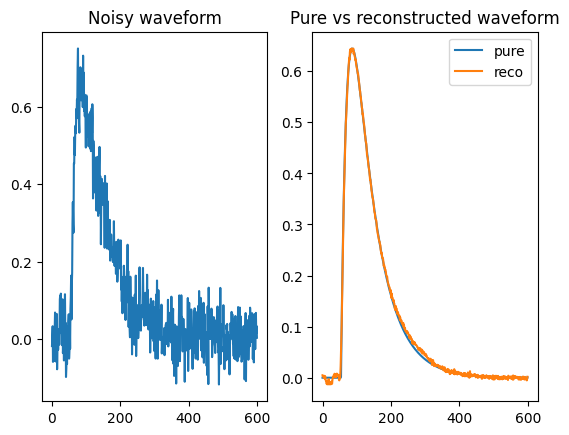

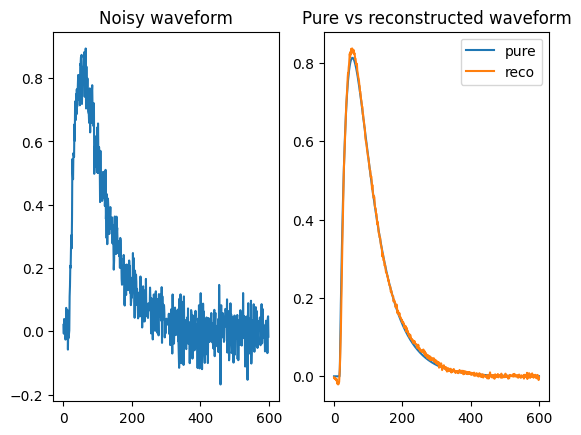

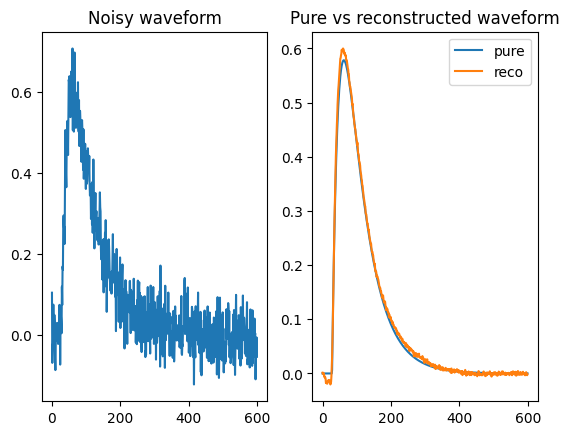

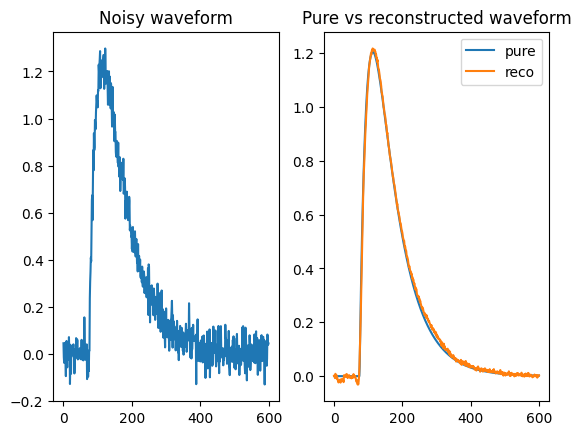

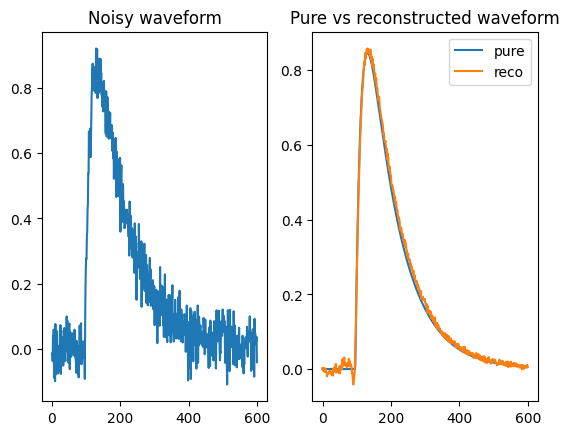

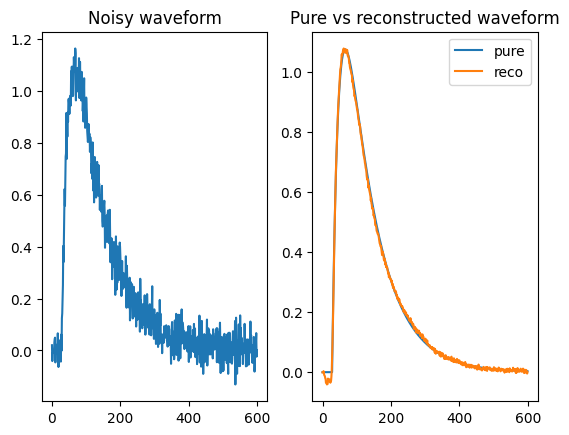

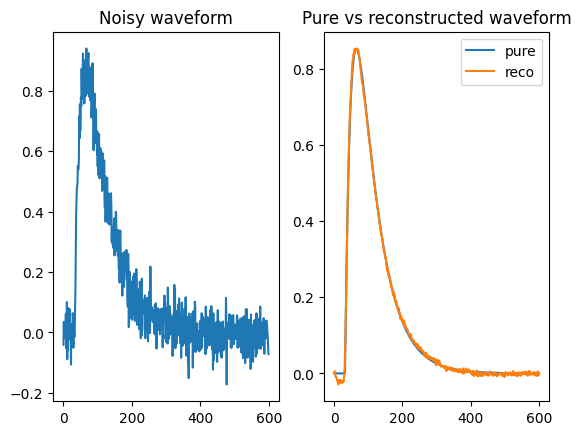

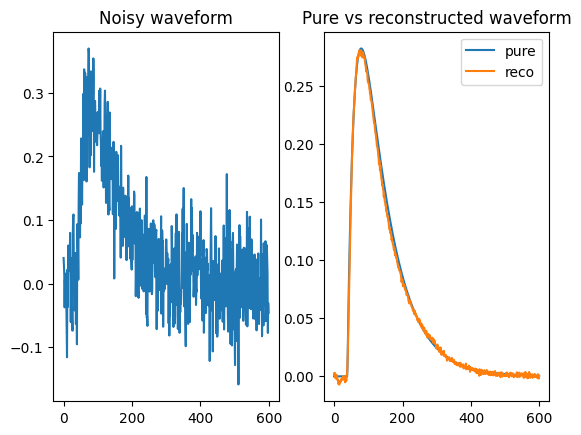

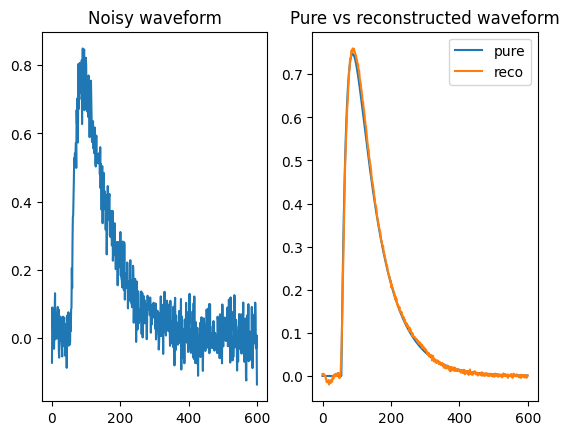

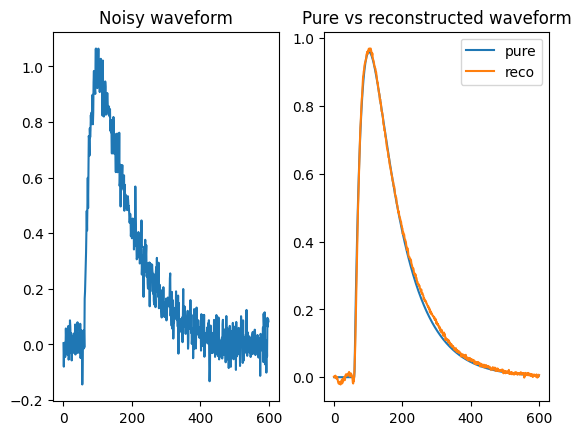

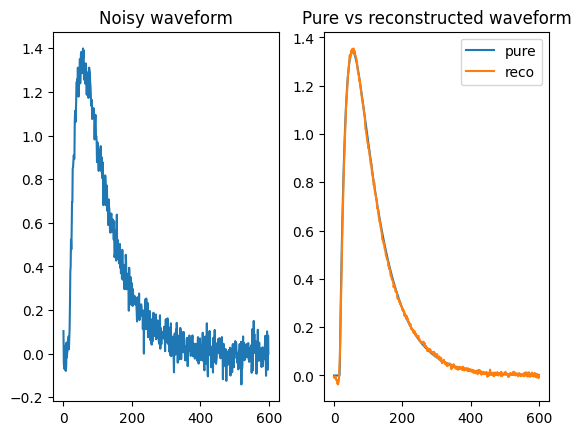

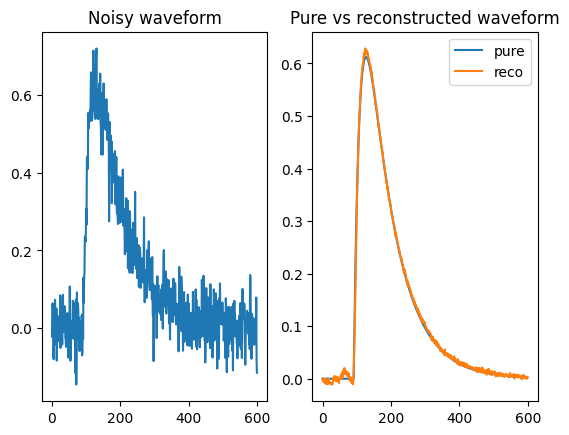

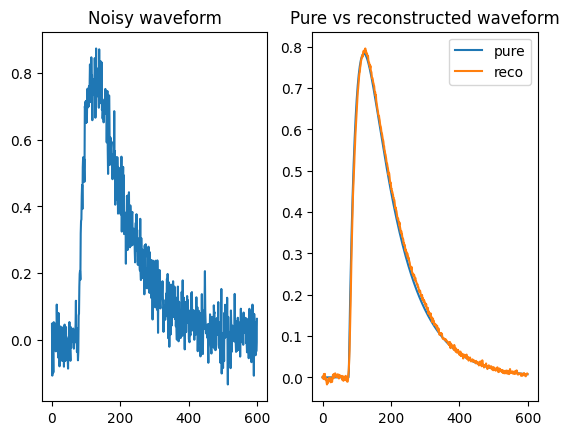

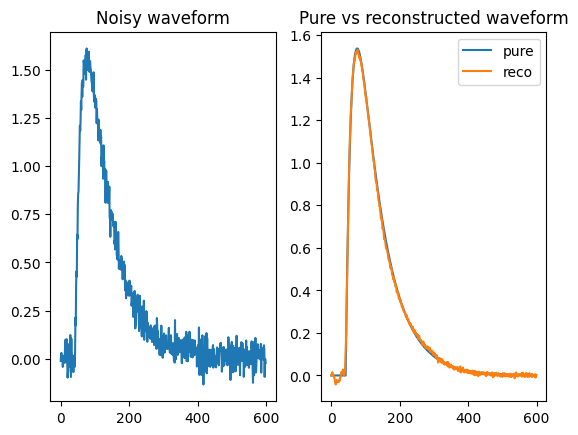

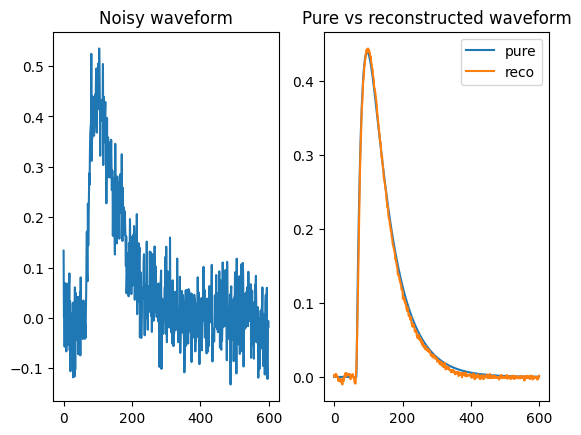

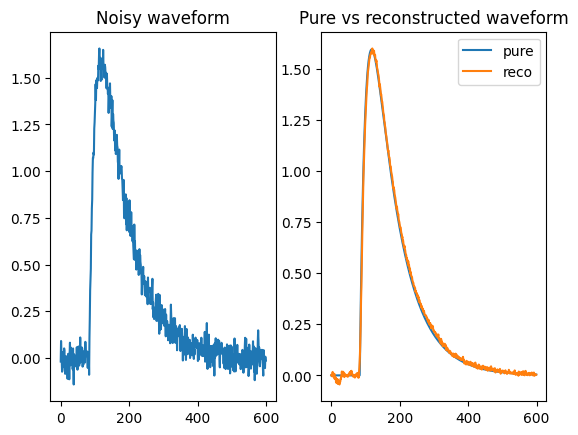

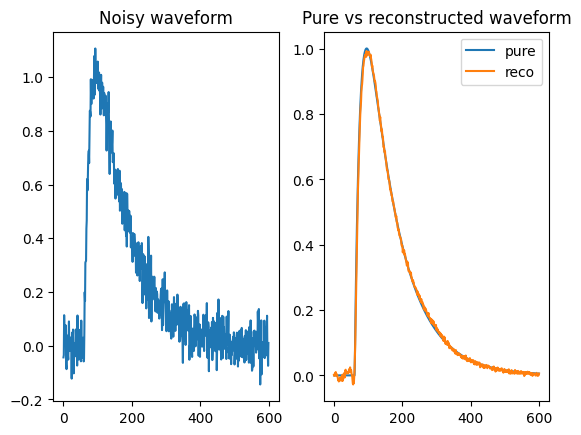

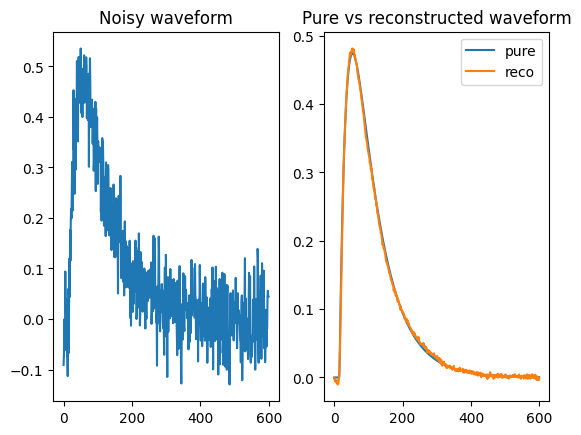

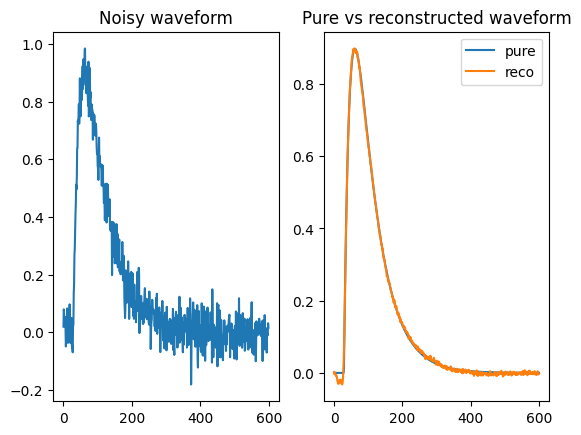

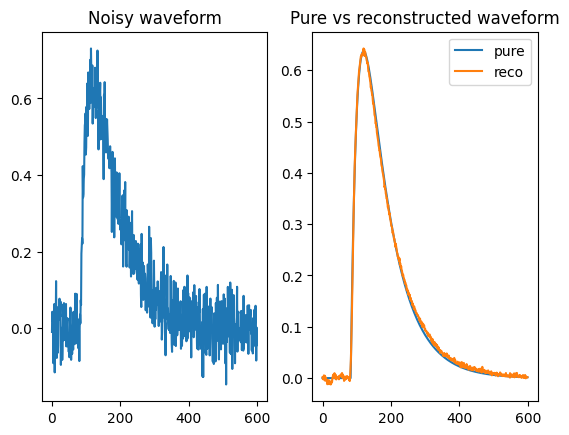

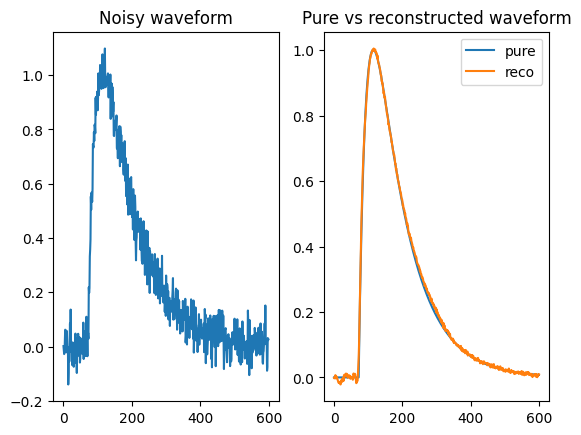

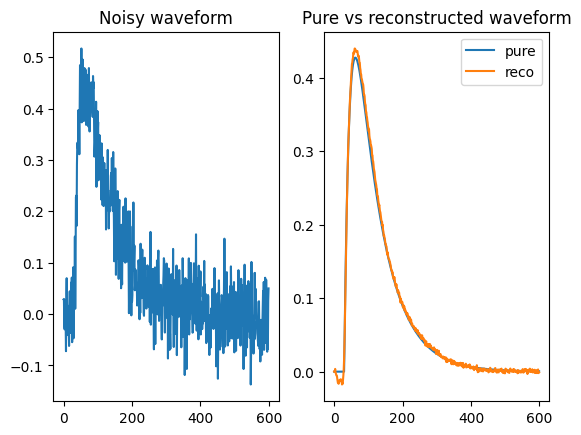

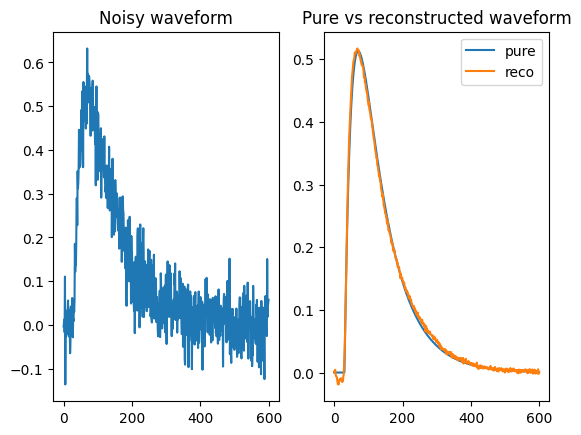

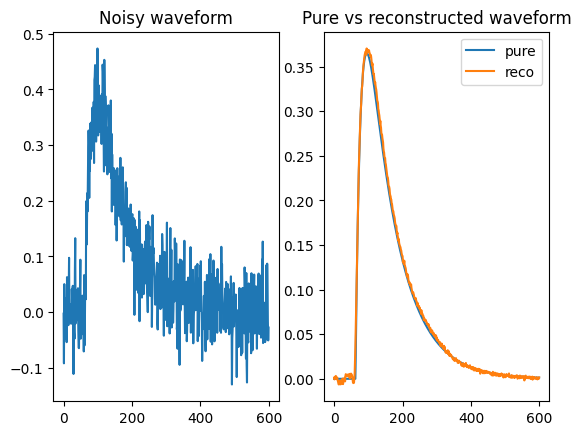

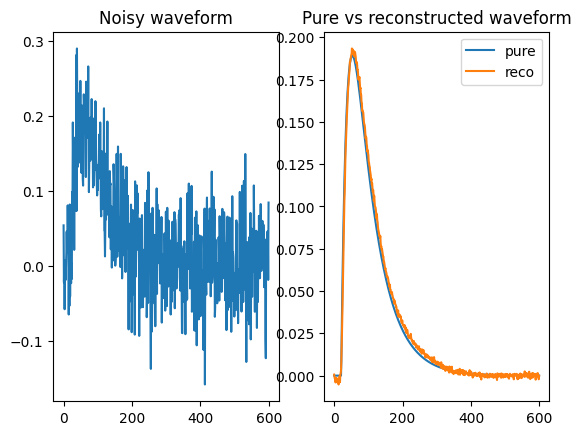

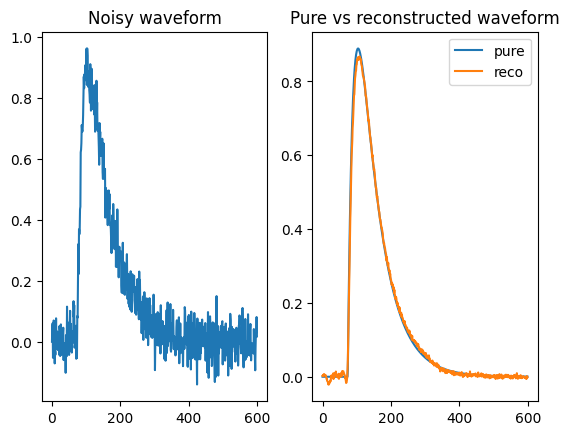

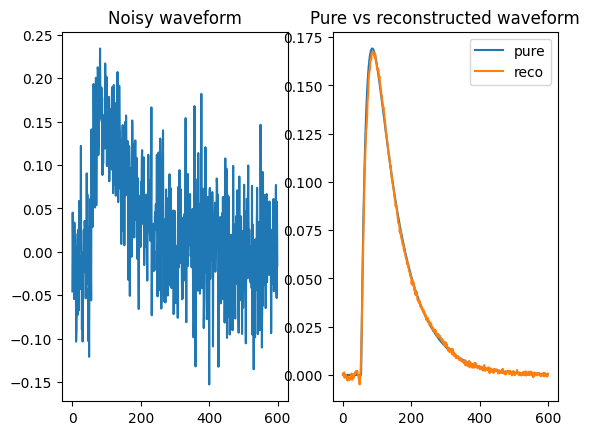

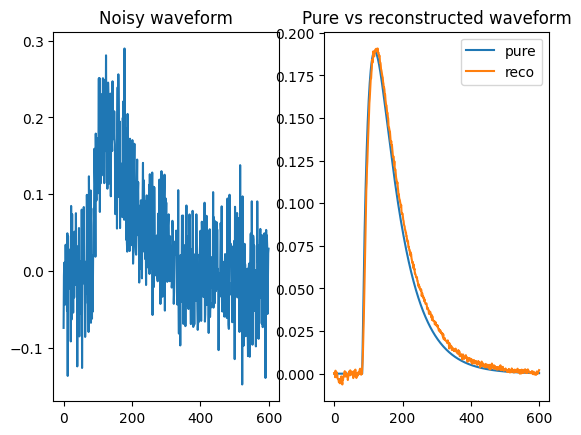

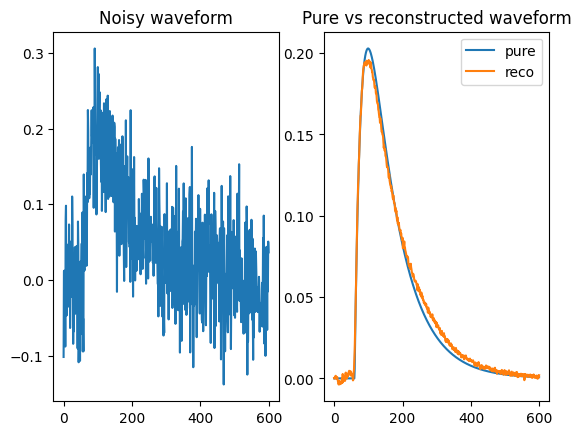

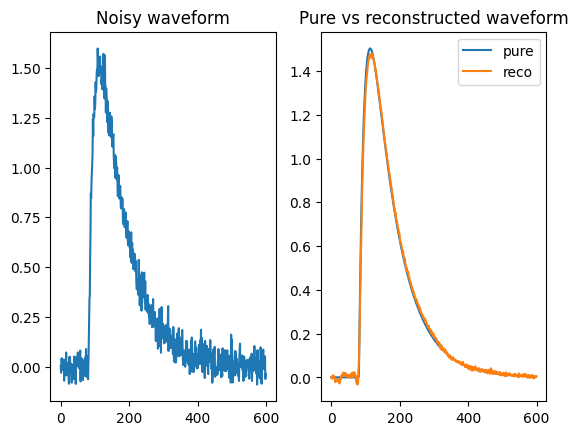

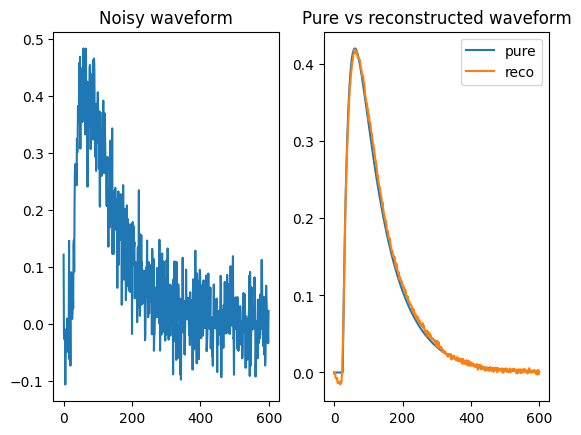

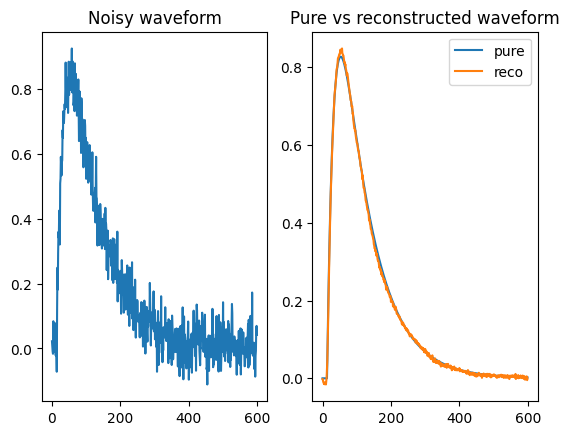

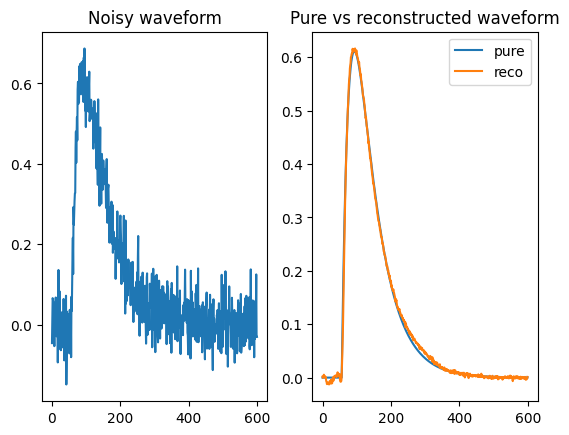

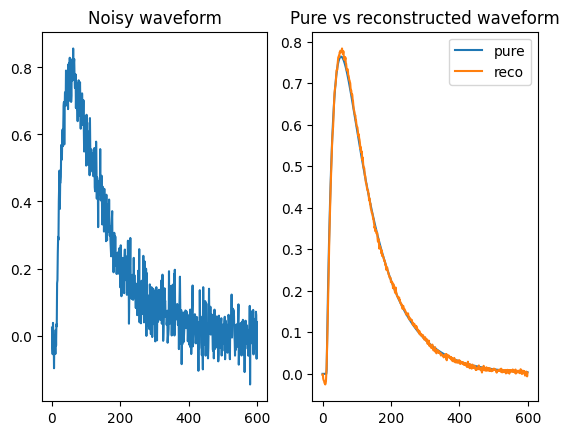

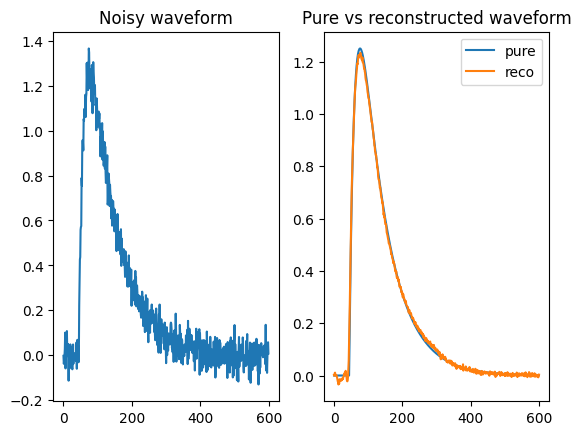

In [ ]:
# Generate reconstructions
num_reconstructions = 100
samples = noisy_input_test[:num_reconstructions]
reconstructions = model.predict(samples)

# Plot reconstructions
for i in np.arange(0, num_reconstructions):
    # Prediction index
    prediction_index = i + percentage_training
    # Get the sample and the reconstruction
    original = y_val_noisy[prediction_index]
    pure = y_val_pure[prediction_index]
    reconstruction = np.array(reconstructions[i] / scale_factors[prediction_index])
    # Matplotlib preparations
    fig, axes = plt.subplots(1, 2)
    # Plot sample and reconstruciton
    axes[0].plot(original)
    axes[0].set_title('Noisy waveform')
    axes[1].plot(pure, label="pure")
    axes[1].set_title('Pure vs reconstructed waveform')
    axes[1].plot(reconstruction, label="reco")
    #axes[1].set_title('Conv Autoencoder Denoised waveform')
    plt.legend(loc='best')
    plt.show()

# Compare the fitted params of the reco shape against the original one

In [ ]:
def fitFunc(t, tauRise, tauDecay, theta, norm):
    return norm * (np.exp(-(t-theta)/tauDecay) - np.exp(-(t-theta)/tauRise))/(tauDecay - tauRise) * (t > theta) #heaviside

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data=None, **kwargs) -> 'list[Line2D]'>

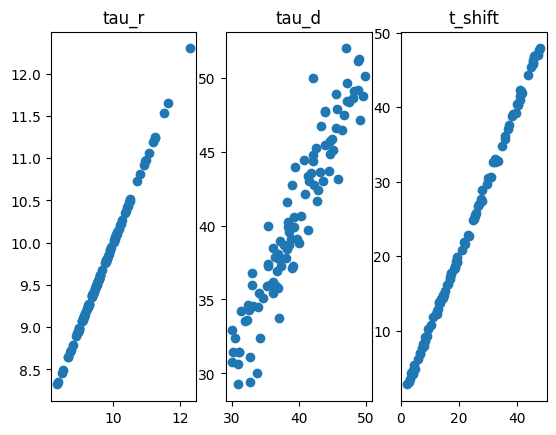

In [ ]:
from scipy.optimize import curve_fit # https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html


initial_guess = np.array([10, 40, 0, 0.5])
bounds = np.array([[0,0,-100, 0],[20,80,100, 100]])

pure_pars_taur = []
pure_pars_taud = []
pure_pars_tshift = []
noisy_pars_taur = []
noisy_pars_taud = []
noisy_pars_tshift = []


for i in np.arange(0, num_reconstructions):
    # Prediction index
    prediction_index = i + percentage_training
    # Get the sample and the reconstruction
    original = y_val_noisy[prediction_index]
    pure = y_val_pure[prediction_index]
    reconstruction = np.array(reconstructions[i] / scale_factors[prediction_index])


    #fit the pure shapes
    popt,pcov = curve_fit(fitFunc, xdata=x_val_pure[prediction_index], ydata=y_val_pure[prediction_index]/np.sum(y_val_pure[prediction_index]),
             p0=initial_guess,
             sigma=None, #else None
             bounds=bounds,#(-np.inf,np.inf)
             )

    perr = (np.diag(pcov))**0.5
    #for i in range(len(popt)):
    #    print('Parametro ', i+1, ': ', popt[i], ' +/- ', perr[i])

    pure_pars_taur.append(popt[0])
    pure_pars_taud.append(popt[1])
    pure_pars_tshift.append(popt[2])


    #fit the reconstructed shapes
    popt,pcov = curve_fit(fitFunc, xdata=x_val_pure[prediction_index], ydata=reconstruction/np.sum(reconstruction),
             p0=initial_guess,
             sigma=None, #else None
             bounds=bounds,#(-np.inf,np.inf)
             )

    perr = (np.diag(pcov))**0.5
    #for i in range(len(popt)):
    #    print('Parametro ', i+1, ': ', popt[i], ' +/- ', perr[i])

    noisy_pars_taur.append(popt[0])
    noisy_pars_taud.append(popt[1])
    noisy_pars_tshift.append(popt[2])

    #x_fit = np.linspace(np.min(x_val_pure[prediction_index]),np.max(x_val_pure[prediction_index]),1000)
    #plt.plot(x_val_pure[prediction_index],reconstruction/np.sum(reconstruction),'o',color='k',label='Data')
    #plt.plot(x_val_pure[prediction_index],fitFunc(x_val_pure[prediction_index],*popt),color='r',label='Fit')


#plot parameters correlation
fig, axes = plt.subplots(1, 3)
axes[0].plot(noisy_pars_taur, noisy_pars_taur, 'o')
axes[0].set_title('tau_r')
axes[1].plot(pure_pars_taud, noisy_pars_taud, 'o')
axes[1].set_title('tau_d')
axes[2].plot(pure_pars_tshift, noisy_pars_tshift, 'o')
axes[2].set_title('t_shift')

plt.plot
